<a href="https://colab.research.google.com/github/umairmalkanirizwi-prog/nlp/blob/main/NLP_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Cell 2: Upload datasets

from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
print(list(uploaded.keys()))

Saving True.csv to True.csv
Saving Fake.csv to Fake.csv
Uploaded files:
['True.csv', 'Fake.csv']


In [ ]:
# Cell 3: Load Fake and True datasets

fake_df = pd.read_csv("Fake.csv")
true_df = pd.read_csv("True.csv")

print("Fake news dataset shape:", fake_df.shape)
print("True news dataset shape:", true_df.shape)

print("\nFake dataset columns:")
print(fake_df.columns.tolist())

print("\nTrue dataset columns:")
print(true_df.columns.tolist())

Fake news dataset shape: (23481, 4)
True news dataset shape: (21417, 4)

Fake dataset columns:
['title', 'text', 'subject', 'date']

True dataset columns:
['title', 'text', 'subject', 'date']


In [ ]:
# Cell 4: Add labels

fake_df["label"] = 0
true_df["label"] = 1

print("Fake news label = 0")
print("True news label = 1")

Fake news label = 0
True news label = 1


In [ ]:
# Cell 5: Combine datasets

df = pd.concat(
    [fake_df, true_df],
    ignore_index=True
)

print("Combined dataset shape:", df.shape)

display(df.head())

Combined dataset shape: (44898, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [ ]:
# Cell 6: Check class distribution

print("Fake news records:", (df["label"] == 0).sum())
print("True news records:", (df["label"] == 1).sum())

print("\nClass distribution:")
print(df["label"].value_counts())

Fake news records: 23481
True news records: 21417

Class distribution:
label
0    23481
1    21417
Name: count, dtype: int64


In [ ]:
# Cell 7: Create news content

df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")

df["content"] = df["title"] + " " + df["text"]

print("News content created successfully!")

display(df[["title", "text", "label"]].head())

News content created successfully!


,title,text,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,0


In [ ]:
# Cell 8: Display examples

print("FAKE NEWS EXAMPLES")
display(
    df[df["label"] == 0][["title", "label"]].head(3)
)

print("\nTRUE NEWS EXAMPLES")
display(
    df[df["label"] == 1][["title", "label"]].head(3)
)

FAKE NEWS EXAMPLES


,title,label
0,Donald Trump Sends Out Embarrassing New Year’...,0
1,Drunk Bragging Trump Staffer Started Russian ...,0
2,Sheriff David Clarke Becomes An Internet Joke...,0



TRUE NEWS EXAMPLES


,title,label
23481,"As U.S. budget fight looms, Republicans flip t...",1
23482,U.S. military to accept transgender recruits o...,1
23483,Senior U.S. Republican senator: 'Let Mr. Muell...,1


In [ ]:
# Cell 9: Clean text

def clean_text(text):

    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["clean_text"] = df["content"].apply(clean_text)

print("Text preprocessing completed!")

print("\nOriginal text:")
print(df["content"].iloc[0][:300])

print("\nCleaned text:")
print(df["clean_text"].iloc[0][:300])

Text preprocessing completed!

Original text:
 Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had j

Cleaned text:
donald trump sends out embarrassing new year’s eve message this is disturbing donald trump just couldn t wish all americans a happy new year and leave it at that instead he had to give a shout out to his enemies haters and the very dishonest fake news media the former reality show star had just one 


In [ ]:
# Cell 10: Remove empty records

df = df[df["clean_text"].str.len() > 0]

df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (44889, 7)


In [ ]:
# Cell 11: Split dataset

X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 35911
Testing samples: 8978

Training label distribution:
label
0    18777
1    17134
Name: count, dtype: int64

Testing label distribution:
label
0    4695
1    4283
Name: count, dtype: int64


In [ ]:
# Cell 12: TF-IDF vectorization

tfidf = TfidfVectorizer(
    stop_words="english",
    max_df=0.7
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF completed!")

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

TF-IDF completed!
Training TF-IDF shape: (35911, 186498)
Testing TF-IDF shape: (8978, 186498)


In [ ]:
# Cell 13: Train model

model = MultinomialNB()

model.fit(
    X_train_tfidf,
    y_train
)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [ ]:
# Cell 14: Make predictions

y_pred = model.predict(X_test_tfidf)

print("Predictions generated successfully!")

print("\nFirst 20 actual labels:")
print(y_test.values[:20])

print("\nFirst 20 predicted labels:")
print(y_pred[:20])

Predictions generated successfully!

First 20 actual labels:
[1 1 0 0 1 0 0 0 1 0 1 0 0 0 0 1 1 1 0 0]

First 20 predicted labels:
[1 1 0 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 0 0]


In [ ]:
# Cell 15: Check predictions

print("Actual label distribution:")
print(pd.Series(y_test).value_counts())

print("\nPredicted label distribution:")
print(pd.Series(y_pred).value_counts())

Actual label distribution:
label
0    4695
1    4283
Name: count, dtype: int64

Predicted label distribution:
0    4689
1    4289
Name: count, dtype: int64


In [ ]:
# Cell 16: Evaluate model

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("MODEL PERFORMANCE")
print("----------------------------")

print("Accuracy  :", round(accuracy * 100, 2), "%")
print("Precision :", round(precision * 100, 2), "%")
print("Recall    :", round(recall * 100, 2), "%")
print("F1-Score  :", round(f1 * 100, 2), "%")

MODEL PERFORMANCE
----------------------------
Accuracy  : 93.94 %
Precision : 93.94 %
Recall    : 93.94 %
F1-Score  : 93.94 %


In [ ]:
# Cell 17: Classification report

print("Classification Report")
print("----------------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["FAKE", "TRUE"]
    )
)

Classification Report
----------------------------
              precision    recall  f1-score   support

        FAKE       0.94      0.94      0.94      4695
        TRUE       0.94      0.94      0.94      4283

    accuracy                           0.94      8978
   macro avg       0.94      0.94      0.94      8978
weighted avg       0.94      0.94      0.94      8978



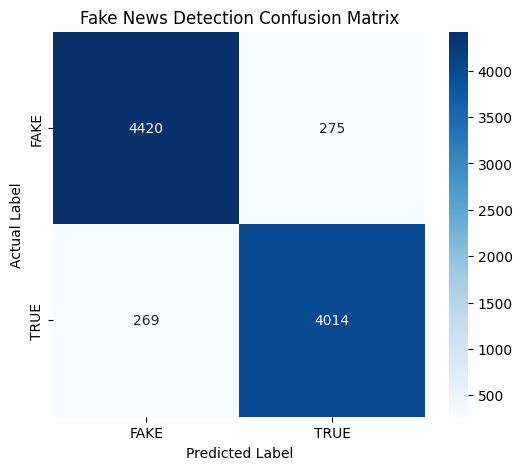

In [ ]:
# Cell 18: Confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["FAKE", "TRUE"],
    yticklabels=["FAKE", "TRUE"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Fake News Detection Confusion Matrix")

plt.show()

In [ ]:
# Cell 19: Test custom news

def predict_news(news):

    cleaned_news = clean_text(news)

    news_tfidf = tfidf.transform([cleaned_news])

    prediction = model.predict(news_tfidf)[0]

    if prediction == 0:
        return "FAKE NEWS"
    else:
        return "TRUE NEWS"


news = input("Enter a news article: ")

result = predict_news(news)

print("\nPrediction:", result)

Enter a news article: trump died

Prediction: FAKE NEWS


In [ ]:
# Cell 20: Final project summary

print("=" * 50)
print("       FAKE NEWS DETECTION USING NLP")
print("=" * 50)

print("Technique: TF-IDF + Multinomial Naive Bayes")

print("Dataset: Fake.csv + True.csv")

print("-" * 50)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("-" * 50)

print("Accuracy  :", round(accuracy * 100, 2), "%")
print("Precision :", round(precision * 100, 2), "%")
print("Recall    :", round(recall * 100, 2), "%")
print("F1-Score  :", round(f1 * 100, 2), "%")

print("=" * 50)
print("Project completed successfully!")

       FAKE NEWS DETECTION USING NLP
Technique: TF-IDF + Multinomial Naive Bayes
Dataset: Fake.csv + True.csv
--------------------------------------------------
Training samples: 35911
Testing samples : 8978
--------------------------------------------------
Accuracy  : 93.94 %
Precision : 93.94 %
Recall    : 93.94 %
F1-Score  : 93.94 %
Project completed successfully!


In [ ]:
# ============================================================
# CELL 21: POLISHED FAKE NEWS DETECTION UI
# ============================================================

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output


# ============================================================
# COLOR THEME
# ============================================================

BG = "#080D1C"
CARD = "#111A2E"
CARD2 = "#17223A"

PRIMARY = "#6366F1"       # Indigo
PRIMARY2 = "#8B5CF6"      # Purple
CYAN = "#06B6D4"
TEXT = "#F8FAFC"
MUTED = "#94A3B8"

SUCCESS = "#22C55E"
SUCCESS_BG = "#0B2E20"

DANGER = "#EF4444"
DANGER_BG = "#35151A"

WARNING = "#F59E0B"
WARNING_BG = "#33240B"

BORDER = "#263653"


# ============================================================
# CUSTOM CSS
# ============================================================

display(HTML(f"""
<style>

    /* Main notebook background */
    .jp-Notebook {{
        background: {BG} !important;
    }}

    /* Textarea */
    textarea {{
        background-color: #0B1326 !important;
        color: {TEXT} !important;
        border: 2px solid {BORDER} !important;
        border-radius: 12px !important;
        padding: 15px !important;
        font-size: 15px !important;
        line-height: 1.6 !important;
    }}

    textarea:focus {{
        border: 2px solid {PRIMARY} !important;
        box-shadow: 0 0 12px rgba(99,102,241,0.25) !important;
    }}

    /* Widget labels */
    .widget-label {{
        color: {TEXT} !important;
        font-weight: 600 !important;
    }}

</style>
"""))


# ============================================================
# HEADER
# ============================================================

title = widgets.HTML(value=f"""

<div style="
    background: linear-gradient(135deg, #111A3A 0%, #312E81 55%, #581C87 100%);
    border: 1px solid #4F46E5;
    padding: 35px 25px;
    border-radius: 20px;
    text-align: center;
    color: {TEXT};
    margin-bottom: 18px;
    box-shadow: 0 10px 30px rgba(0,0,0,0.35);
">

    <div style="
        font-size: 46px;
        margin-bottom: 8px;
    ">
        📰
    </div>

    <div style="
        font-size: 38px;
        font-weight: 800;
        letter-spacing: 0.5px;
    ">
        Fake News Detector
    </div>

    <div style="
        font-size: 17px;
        color: #C7D2FE;
        margin-top: 10px;
    ">
        NLP-Powered Fake & True News Classification
    </div>

    <div style="
        display:inline-block;
        margin-top:18px;
        padding:7px 16px;
        background:rgba(255,255,255,0.10);
        border:1px solid rgba(255,255,255,0.18);
        border-radius:20px;
        font-size:13px;
        color:#E0E7FF;
    ">
        🔬 Machine Learning • NLP • Text Classification
    </div>

</div>
""")


# ============================================================
# MODEL INFORMATION CARDS
# ============================================================

info = widgets.HTML(value=f"""

<div style="
    display:flex;
    gap:14px;
    margin-bottom:18px;
    flex-wrap:wrap;
">

    <div style="
        flex:1;
        min-width:200px;
        background:{CARD};
        border:1px solid {BORDER};
        padding:18px;
        border-radius:14px;
    ">

        <div style="
            color:{CYAN};
            font-size:13px;
            font-weight:600;
        ">
            🧠 NLP TECHNIQUE
        </div>

        <div style="
            color:{TEXT};
            font-size:17px;
            font-weight:700;
            margin-top:7px;
        ">
            TF-IDF
        </div>

    </div>


    <div style="
        flex:1;
        min-width:200px;
        background:{CARD};
        border:1px solid {BORDER};
        padding:18px;
        border-radius:14px;
    ">

        <div style="
            color:{PRIMARY2};
            font-size:13px;
            font-weight:600;
        ">
            🤖 ML MODEL
        </div>

        <div style="
            color:{TEXT};
            font-size:17px;
            font-weight:700;
            margin-top:7px;
        ">
            Multinomial Naive Bayes
        </div>

    </div>


    <div style="
        flex:1;
        min-width:200px;
        background:{CARD};
        border:1px solid {BORDER};
        padding:18px;
        border-radius:14px;
    ">

        <div style="
            color:{SUCCESS};
            font-size:13px;
            font-weight:600;
        ">
            🎯 CLASSES
        </div>

        <div style="
            color:{TEXT};
            font-size:17px;
            font-weight:700;
            margin-top:7px;
        ">
            FAKE / TRUE
        </div>

    </div>

</div>
""")


# ============================================================
# INPUT SECTION TITLE
# ============================================================

input_title = widgets.HTML(value=f"""

<div style="
    background:{CARD};
    border:1px solid {BORDER};
    border-bottom:none;
    padding:18px 20px 10px 20px;
    border-radius:14px 14px 0 0;
">

    <div style="
        color:{TEXT};
        font-size:20px;
        font-weight:700;
    ">
        ✍️ Enter News Article
    </div>

    <div style="
        color:{MUTED};
        font-size:13px;
        margin-top:5px;
    ">
        Paste or type the news article you want to analyze.
    </div>

</div>
""")


# ============================================================
# NEWS INPUT BOX
# ============================================================

news_input = widgets.Textarea(

    placeholder="Paste or type a news article here...",

    layout=widgets.Layout(
        width="100%",
        height="210px"
    ),

    style={
        "description_width": "0px"
    }
)


# ============================================================
# BUTTONS
# ============================================================

predict_button = widgets.Button(

    description="🔍  Analyze News",

    layout=widgets.Layout(
        width="190px",
        height="48px",
        margin="12px 8px 12px 0"
    ),

    style={
        "button_color": PRIMARY,
        "font_weight": "bold"
    }
)


clear_button = widgets.Button(

    description="🗑  Clear",

    layout=widgets.Layout(
        width="120px",
        height="48px",
        margin="12px 0"
    ),

    style={
        "button_color": "#334155",
        "font_weight": "bold"
    }
)


# ============================================================
# OUTPUT
# ============================================================

output = widgets.Output()


# ============================================================
# PREDICTION FUNCTION
# ============================================================

def predict_news_ui(b):

    with output:

        clear_output()

        news = news_input.value.strip()


        # ----------------------------------------------------
        # EMPTY INPUT
        # ----------------------------------------------------

        if not news:

            display(
                HTML(
                    f"""
                    <div style="
                        background:{WARNING_BG};
                        border:1px solid {WARNING};
                        color:{WARNING};
                        padding:18px;
                        border-radius:12px;
                        margin-top:15px;
                        text-align:center;
                        font-size:15px;
                    ">

                    ⚠️ <b>Please enter a news article first.</b>

                    <div style="
                        color:#D6B96C;
                        margin-top:5px;
                        font-size:13px;
                    ">
                        Enter some news text and click Analyze News.
                    </div>

                    </div>
                    """
                )
            )

            return


        # ----------------------------------------------------
        # CLEAN TEXT
        # ----------------------------------------------------

        cleaned_news = clean_text(news)


        # ----------------------------------------------------
        # TF-IDF
        # ----------------------------------------------------

        news_tfidf = tfidf.transform(
            [cleaned_news]
        )


        # ----------------------------------------------------
        # PREDICTION
        # ----------------------------------------------------

        prediction = model.predict(
            news_tfidf
        )[0]


        # ----------------------------------------------------
        # PROBABILITIES
        # ----------------------------------------------------

        probabilities = model.predict_proba(
            news_tfidf
        )[0]


        fake_probability = probabilities[0] * 100
        true_probability = probabilities[1] * 100


        # ----------------------------------------------------
        # FAKE RESULT
        # ----------------------------------------------------

        if prediction == 0:

            result = f"""

            <div style="
                background:linear-gradient(145deg, {DANGER_BG}, #24131A);
                border:1px solid {DANGER};
                padding:28px;
                border-radius:18px;
                margin-top:18px;
                text-align:center;
                color:{TEXT};
                box-shadow:0 8px 25px rgba(239,68,68,0.15);
            ">

                <div style="
                    font-size:52px;
                    margin-bottom:5px;
                ">
                    ⚠️
                </div>

                <div style="
                    font-size:32px;
                    font-weight:800;
                    color:{DANGER};
                ">
                    FAKE NEWS
                </div>

                <div style="
                    color:{MUTED};
                    margin-top:7px;
                    font-size:14px;
                ">
                    The model classified this article as
                    <b style="color:{DANGER};">FAKE</b>.
                </div>


                <div style="
                    margin-top:25px;
                    text-align:left;
                ">

                    <div style="
                        display:flex;
                        justify-content:space-between;
                        margin-bottom:7px;
                    ">
                        <span>🚨 Fake Probability</span>
                        <b>{fake_probability:.2f}%</b>
                    </div>

                    <div style="
                        height:12px;
                        background:#461923;
                        border-radius:20px;
                        overflow:hidden;
                    ">

                        <div style="
                            width:{fake_probability}%;
                            height:100%;
                            background:{DANGER};
                            border-radius:20px;
                        "></div>

                    </div>


                    <div style="
                        display:flex;
                        justify-content:space-between;
                        margin-top:18px;
                        margin-bottom:7px;
                    ">
                        <span>✅ True Probability</span>
                        <b>{true_probability:.2f}%</b>
                    </div>

                    <div style="
                        height:12px;
                        background:#183528;
                        border-radius:20px;
                        overflow:hidden;
                    ">

                        <div style="
                            width:{true_probability}%;
                            height:100%;
                            background:{SUCCESS};
                            border-radius:20px;
                        "></div>

                    </div>

                </div>

            </div>
            """


        # ----------------------------------------------------
        # TRUE RESULT
        # ----------------------------------------------------

        else:

            result = f"""

            <div style="
                background:linear-gradient(145deg, {SUCCESS_BG}, #0D2118);
                border:1px solid {SUCCESS};
                padding:28px;
                border-radius:18px;
                margin-top:18px;
                text-align:center;
                color:{TEXT};
                box-shadow:0 8px 25px rgba(34,197,94,0.15);
            ">

                <div style="
                    font-size:52px;
                    margin-bottom:5px;
                ">
                    ✅
                </div>

                <div style="
                    font-size:32px;
                    font-weight:800;
                    color:{SUCCESS};
                ">
                    TRUE NEWS
                </div>

                <div style="
                    color:{MUTED};
                    margin-top:7px;
                    font-size:14px;
                ">
                    The model classified this article as
                    <b style="color:{SUCCESS};">TRUE</b>.
                </div>


                <div style="
                    margin-top:25px;
                    text-align:left;
                ">

                    <div style="
                        display:flex;
                        justify-content:space-between;
                        margin-bottom:7px;
                    ">
                        <span>🚨 Fake Probability</span>
                        <b>{fake_probability:.2f}%</b>
                    </div>

                    <div style="
                        height:12px;
                        background:#461923;
                        border-radius:20px;
                        overflow:hidden;
                    ">

                        <div style="
                            width:{fake_probability}%;
                            height:100%;
                            background:{DANGER};
                            border-radius:20px;
                        "></div>

                    </div>


                    <div style="
                        display:flex;
                        justify-content:space-between;
                        margin-top:18px;
                        margin-bottom:7px;
                    ">
                        <span>✅ True Probability</span>
                        <b>{true_probability:.2f}%</b>
                    </div>

                    <div style="
                        height:12px;
                        background:#183528;
                        border-radius:20px;
                        overflow:hidden;
                    ">

                        <div style="
                            width:{true_probability}%;
                            height:100%;
                            background:{SUCCESS};
                            border-radius:20px;
                        "></div>

                    </div>

                </div>

            </div>
            """


        # ----------------------------------------------------
        # DISPLAY RESULT
        # ----------------------------------------------------

        display(
            HTML(result)
        )


        # ----------------------------------------------------
        # DISCLAIMER
        # ----------------------------------------------------

        display(
            HTML(
                f"""

                <div style="
                    background:{CARD};
                    border:1px solid {BORDER};
                    color:{MUTED};
                    padding:14px 18px;
                    border-radius:12px;
                    margin-top:12px;
                    text-align:center;
                    font-size:12px;
                ">

                    ℹ️ <b style="color:{TEXT};">Disclaimer:</b>
                    This system performs machine-learning classification
                    based on patterns learned from the training dataset.
                    It does not independently verify facts.

                </div>

                """
            )
        )


# ============================================================
# CLEAR FUNCTION
# ============================================================

def clear_text(b):

    news_input.value = ""

    with output:

        clear_output()


# ============================================================
# CONNECT BUTTONS
# ============================================================

predict_button.on_click(
    predict_news_ui
)

clear_button.on_click(
    clear_text
)


# ============================================================
# DISPLAY COMPLETE UI
# ============================================================

display(title)

display(info)

display(input_title)

display(news_input)

display(
    widgets.HBox(
        [
            predict_button,
            clear_button
        ]
    )
)

display(output)

HTML(value='\n\n<div style="\n    background: linear-gradient(135deg, #111A3A 0%, #312E81 55%, #581C87 100%);\…

HTML(value='\n\n<div style="\n    display:flex;\n    gap:14px;\n    margin-bottom:18px;\n    flex-wrap:wrap;\n…

HTML(value='\n\n<div style="\n    background:#111A2E;\n    border:1px solid #263653;\n    border-bottom:none;\…

Textarea(value='', layout=Layout(height='210px', width='100%'), placeholder='Paste or type a news article here…

Output()